In [1]:
# Cell 1: Imports and student configuration
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

student_name = "Gualberto"
student_id = "TUPM-26-1130"
id_num = int(student_id[-3:])

color1 = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"
color2 = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4) % 256:02x}"

dataset_path = Path("spotify_dataset") / "spotify_top_1000_tracks.csv"

print("Student:", student_name, "|", student_id)
print("id_num:", id_num, "| color1:", color1, "| color2:", color2)
print("Dataset found:", dataset_path.exists())

Student: Gualberto | TUPM-26-1130
id_num: 130 | color1: #8e868a | color2: #049208
Dataset found: True


In [2]:
# Cell 2: Load and preprocess the dataset
df = pd.read_csv(dataset_path, encoding="utf-8")

df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year

print("Dataset loaded and basic preprocessing complete!")
print(df.head(3))

Dataset loaded and basic preprocessing complete!
                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9YMctZqd1...  7MXVkk9YMctZqd1Srtv4MB   
2  https://open.spotify.com/track/0TK2YIli7K1leLo...  0TK2YIli7K1leLovkQiNik   

   duration_min    year  
0      3.869767  2018.0  
1      3.840883  2016.0  
2      3.182667  2019.0  


In [3]:
# Cell 3: Data cleaning and feature engineering
df['track_name'] = df['track_name'].str.strip()
df['artist'] = df['artist'].str.strip()
df['album'] = df['album'].str.strip()

df['year'] = df['year'].fillna(0).astype(int)

cols_to_drop = ['spotify_url', 'id', 'release_date']

if 'time_signature' in df.columns:
    cols_to_drop.append('time_signature')
if 'key' in df.columns:
    cols_to_drop.append('key')
if 'mode' in df.columns:
    cols_to_drop.append('mode')

df = df.drop(columns=cols_to_drop, errors='ignore')

tempo_bins = [0, 100, 140, np.inf]
tempo_labels = ['Slow', 'Medium', 'Fast']

if 'tempo' in df.columns:
    df['tempo_category'] = pd.cut(
        df['tempo'], bins=tempo_bins,
        labels=tempo_labels, right=False
    )
    print("Feature 'tempo_category' created.")
else:
    print("Warning: 'tempo' column not found; skipping 'tempo_category' creation.")

df = df.drop_duplicates(subset=['track_name', 'artist'], keep='first')

print("Data cleaning and feature engineering complete.")
print(f"Final Row Count after deduplication: {len(df)}")

Data cleaning and feature engineering complete.
Final Row Count after deduplication: 971


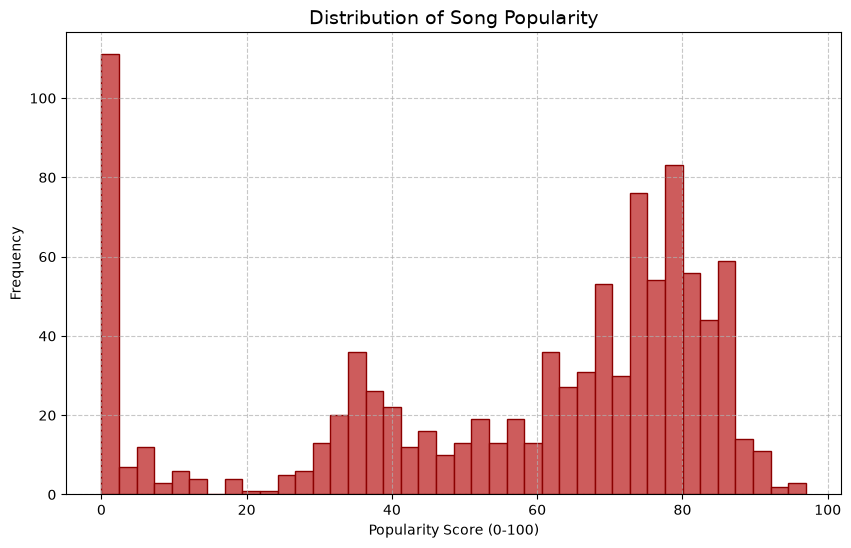

In [4]:
# Cell 4: 1. Histogram - Distribution of Song Popularity
plt.figure(figsize=(10, 6))
plt.hist(df['popularity'], bins=40, color='indianred', edgecolor='darkred')
plt.title('Distribution of Song Popularity', fontsize=14)
plt.xlabel('Popularity Score (0-100)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

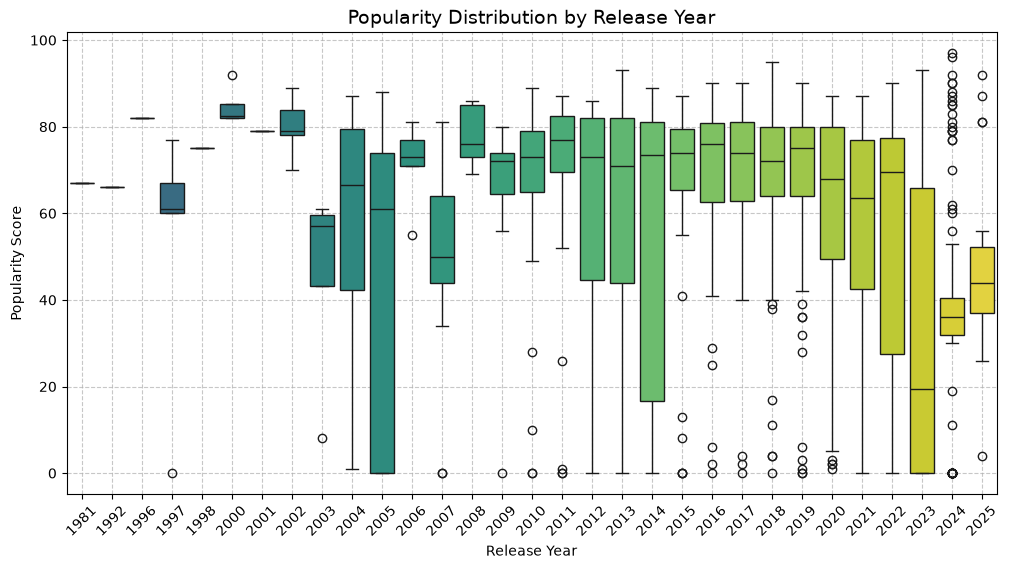

In [5]:
# Cell 5: 2. Boxplot - Popularity Distribution by Release Year
df_years = df[df['year'] > 0]

plt.figure(figsize=(12, 6))
sns.boxplot(x='year', y='popularity', data=df_years, hue='year',
            palette='viridis', legend=False)
plt.title('Popularity Distribution by Release Year', fontsize=14)
plt.xlabel('Release Year')
plt.ylabel('Popularity Score')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

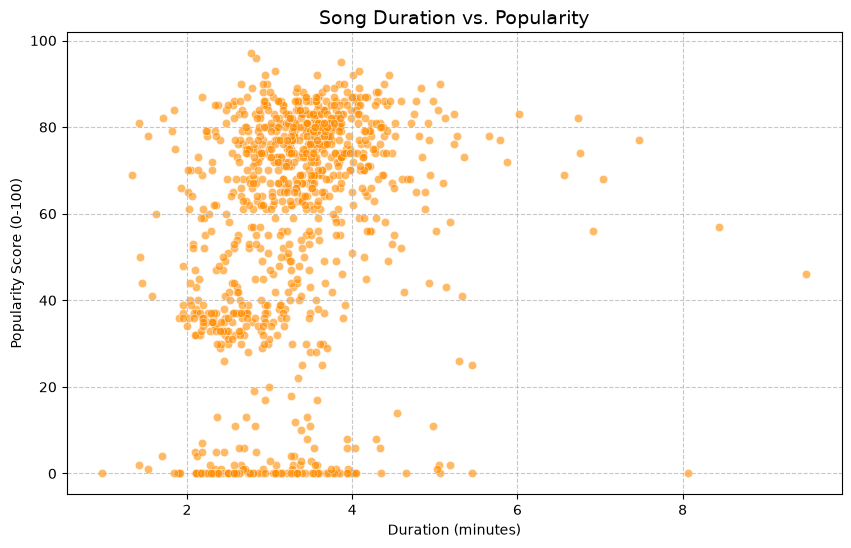

In [6]:
# Cell 6: 3. Scatter Plot - Duration vs Popularity
plt.figure(figsize=(10, 6))
sns.scatterplot(x='duration_min', y='popularity', data=df, alpha=0.6, color='darkorange')
plt.title('Song Duration vs. Popularity', fontsize=14)
plt.xlabel('Duration (minutes)')
plt.ylabel('Popularity Score (0-100)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

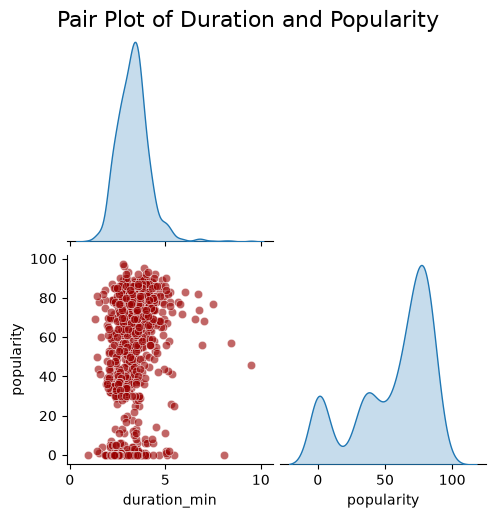

In [7]:
# Cell 7: 4. Pair Plot - Feature Relationships Overview
key_features = ['duration_min', 'popularity']

g = sns.pairplot(
    df[key_features],
    diag_kind='kde',
    corner=True,
    plot_kws={'alpha': 0.6, 'color': '#990000'}
)
g.figure.suptitle('Pair Plot of Duration and Popularity', y=1.02, fontsize=16)
plt.show()

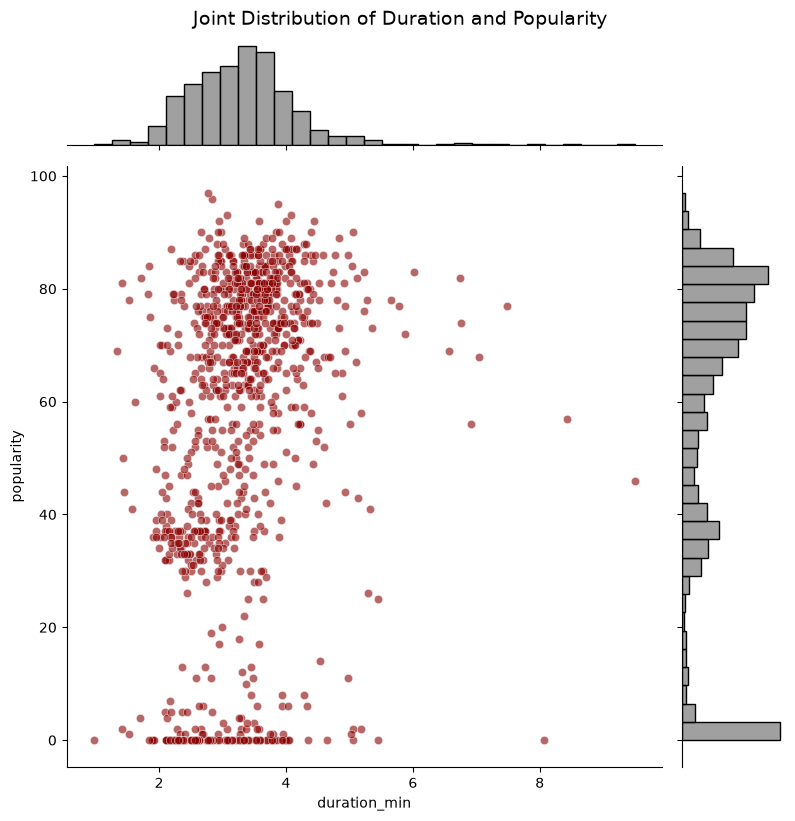

In [8]:
# Cell 8: 5. Joint Plot - Duration vs Popularity Distribution
g = sns.jointplot(
    x='duration_min',
    y='popularity',
    data=df,
    kind='scatter',
    height=8,
    marginal_kws={'bins': 30, 'color': 'gray', 'edgecolor': 'black'},
    joint_kws={'alpha': 0.6, 'color': 'darkred'}
)
g.figure.suptitle('Joint Distribution of Duration and Popularity', y=1.02, fontsize=14)
plt.show()

GIF saved successfully at: c:\Users\Admin\Lab8_Data_Visualization_Gualberto\yearly_popularity_trend.gif


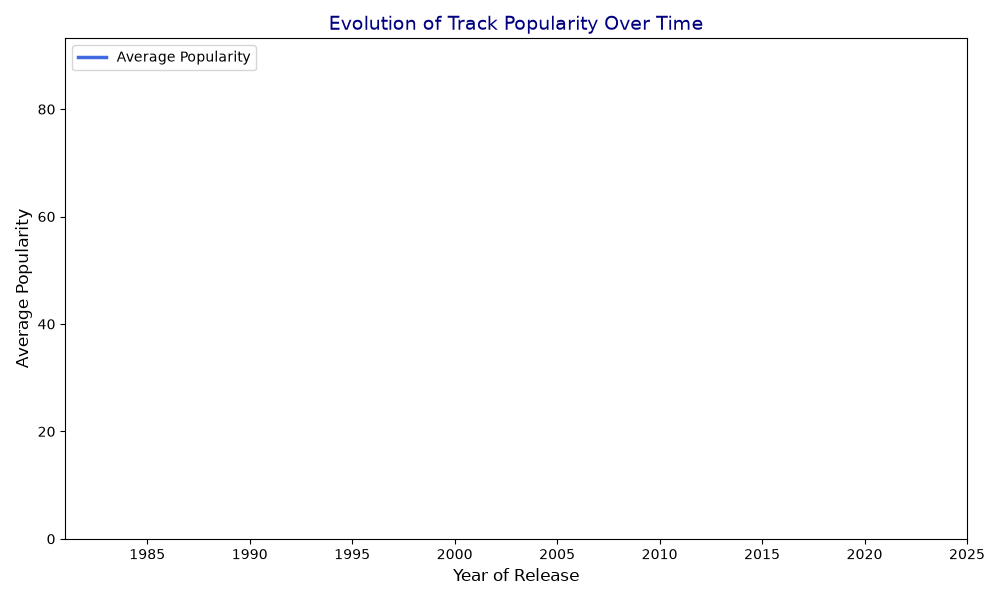

True

In [9]:
# Cell 9: 6. Animated Line Chart - Evolution of Average Popularity Over Time
import webbrowser
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

anim_df = pd.read_csv(dataset_path)
anim_df['release_date'] = pd.to_datetime(anim_df['release_date'], errors='coerce')
anim_df['year'] = anim_df['release_date'].dt.year
anim_df = anim_df.dropna(subset=['year'])

yearly_popularity = anim_df.groupby('year')['popularity'].mean().reset_index()
yearly_popularity = yearly_popularity.sort_values('year')

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(yearly_popularity['year'].min(), yearly_popularity['year'].max())
ax.set_ylim(0, yearly_popularity['popularity'].max() * 1.1)
line, = ax.plot([], [], color='royalblue', linewidth=2.5, label='Average Popularity')
ax.set_title("Evolution of Track Popularity Over Time", fontsize=14, color='navy')
ax.set_xlabel("Year of Release", fontsize=12)
ax.set_ylabel("Average Popularity", fontsize=12)
ax.legend(loc="upper left")
plt.tight_layout()

def animate(i):
    x = yearly_popularity['year'].iloc[:i + 1]
    y = yearly_popularity['popularity'].iloc[:i + 1]
    line.set_data(x, y)
    return line,

ani = FuncAnimation(fig, animate, frames=len(yearly_popularity), interval=100, repeat=False)

gif_path = os.path.abspath("yearly_popularity_trend.gif")
ani.save(gif_path, writer=PillowWriter(fps=10))
print(f"GIF saved successfully at: {gif_path}")

plt.close(fig)
display(Image(filename=gif_path))
webbrowser.open(f"file://{gif_path}")

In [10]:
# Cell 10: Section IV preparation (release_year and decade columns)
df['release_year'] = df['year'].replace(0, np.nan)
df['decade'] = (df['release_year'] // 10) * 10

print(df[['year', 'release_year', 'decade']].head())

   year  release_year  decade
0  2018        2018.0  2010.0
1  2016        2016.0  2010.0
2  2019        2019.0  2010.0
3  2020        2020.0  2020.0
4  2016        2016.0  2010.0


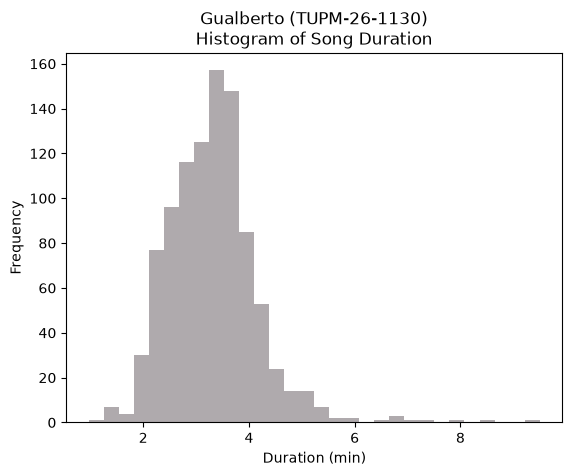

In [11]:
# Cell 11: Section IV #1 - Histogram of Song Duration
df['duration_min'].plot(kind='hist', bins=30, color=color1, alpha=0.7)
plt.title(f"{student_name} ({student_id})\nHistogram of Song Duration")
plt.xlabel('Duration (min)')
plt.ylabel('Frequency')
plt.show()

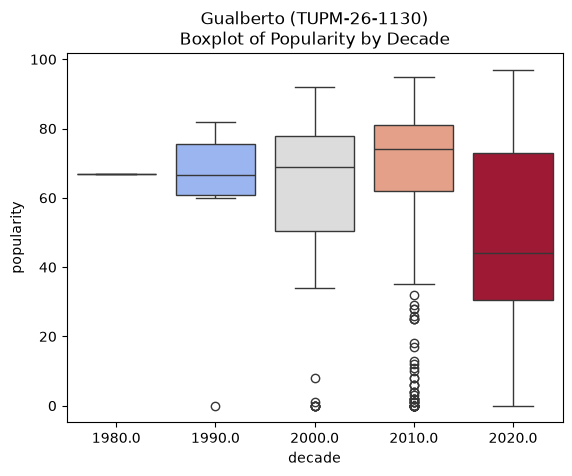

In [12]:
# Cell 12: Section IV #2 - Boxplot of Popularity by Decade
sns.boxplot(x='decade', y='popularity', data=df.dropna(subset=['decade']),
            hue='decade', palette='coolwarm', legend=False)
plt.title(f"{student_name} ({student_id})\nBoxplot of Popularity by Decade")
plt.show()

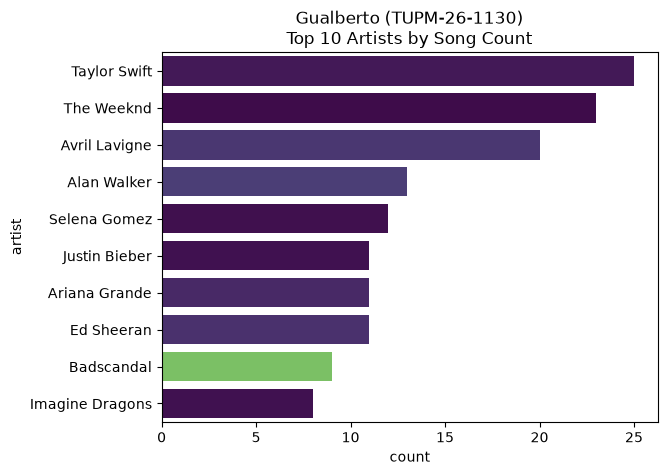

In [13]:
# Cell 13: Section IV #3 - Top 10 Artists by Song Count
sns.countplot(y='artist', data=df, order=df['artist'].value_counts().head(10).index,
              hue='artist', palette='viridis', legend=False)
plt.title(f"{student_name} ({student_id})\nTop 10 Artists by Song Count")
plt.show()

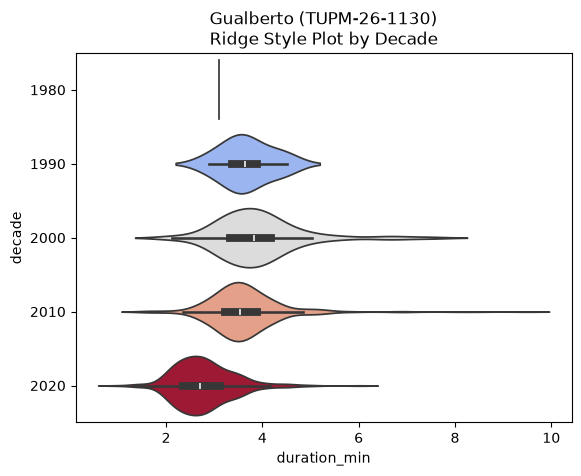

In [14]:
# Cell 14: Section IV #4 - Ridge Style Plot by Decade
df_decade = df.dropna(subset=['decade']).copy()
df_decade['decade'] = df_decade['decade'].astype(int)

sns.violinplot(data=df_decade, x='duration_min', y='decade', orient='h',
               hue='decade', palette='coolwarm', density_norm='width', legend=False)
plt.title(f"{student_name} ({student_id})\nRidge Style Plot by Decade")
plt.show()

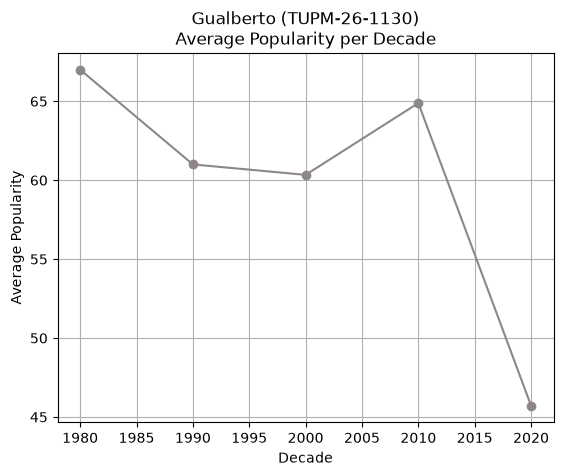

In [15]:
# Cell 15: Section IV #5 - Average Popularity per Decade
avg_pop = df.groupby('decade')['popularity'].mean()
avg_pop.plot(kind='line', color=color1, marker='o')
plt.title(f"{student_name} ({student_id})\nAverage Popularity per Decade")
plt.xlabel('Decade')
plt.ylabel('Average Popularity')
plt.grid(True)
plt.show()

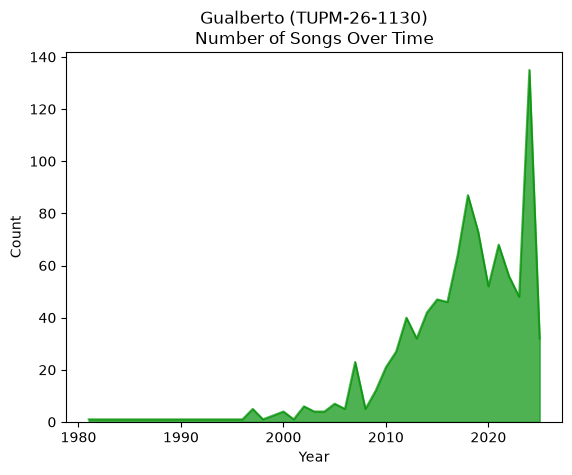

In [16]:
# Cell 16: Section IV #6 - Number of Songs Over Time
count_by_year = df['release_year'].dropna().astype(int).value_counts().sort_index()
count_by_year.plot(kind='area', color=color2, alpha=0.7)
plt.title(f"{student_name} ({student_id})\nNumber of Songs Over Time")
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()

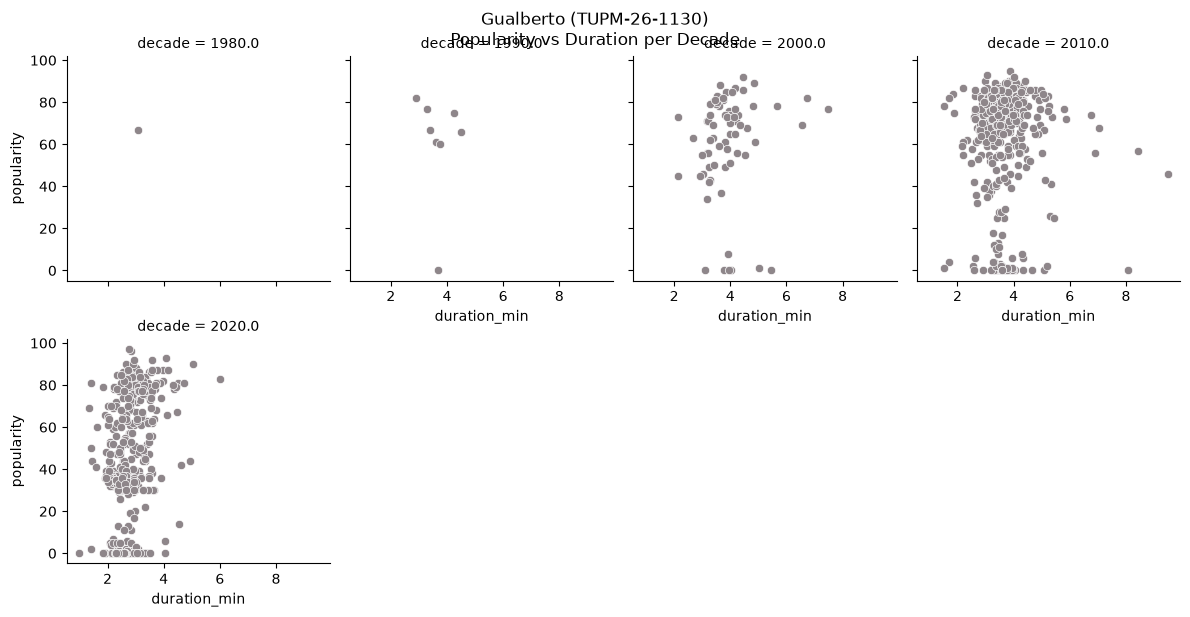

In [17]:
# Cell 17: Section IV #7 - Popularity vs Duration per Decade
g = sns.FacetGrid(df.dropna(subset=['decade']), col='decade', col_wrap=4, height=3)
g.map_dataframe(sns.scatterplot, x='duration_min', y='popularity', color=color1)
g.figure.suptitle(f"{student_name} ({student_id})\nPopularity vs Duration per Decade", y=1.02)
plt.show()

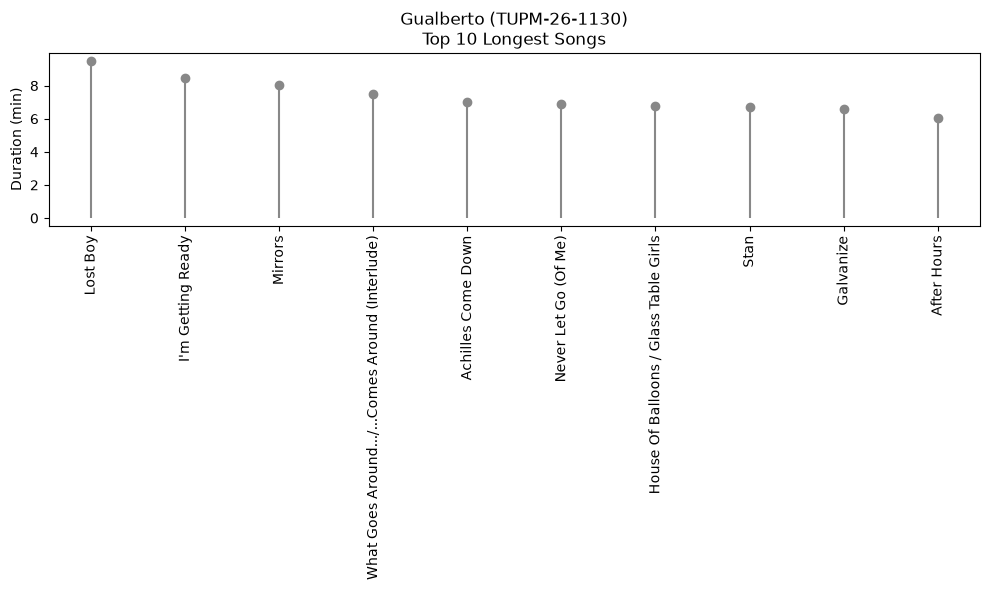

In [18]:
# Cell 18: Section IV #8 - Top 10 Longest Songs
longest = df.nlargest(10, 'duration_min')
plt.figure(figsize=(10, 6))
plt.stem(range(len(longest)), longest['duration_min'], linefmt='#888888', markerfmt='o', basefmt=" ")
plt.xticks(range(len(longest)), longest['track_name'], rotation=90)
plt.title(f"{student_name} ({student_id})\nTop 10 Longest Songs")
plt.ylabel('Duration (min)')
plt.tight_layout()
plt.show()

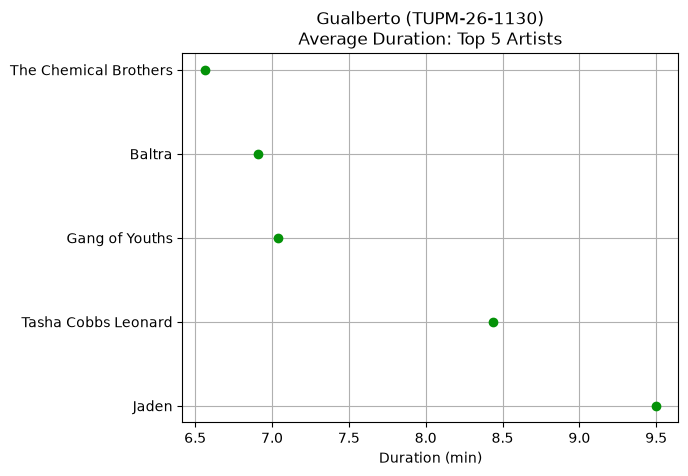

In [19]:
# Cell 19: Section IV #9 - Average Duration: Top 5 Artists
avg_duration = df.groupby('artist')['duration_min'].mean().nlargest(5)
plt.plot(avg_duration.values, avg_duration.index, 'o', color=color2)
plt.title(f"{student_name} ({student_id})\nAverage Duration: Top 5 Artists")
plt.xlabel('Duration (min)')
plt.grid(True)
plt.show()

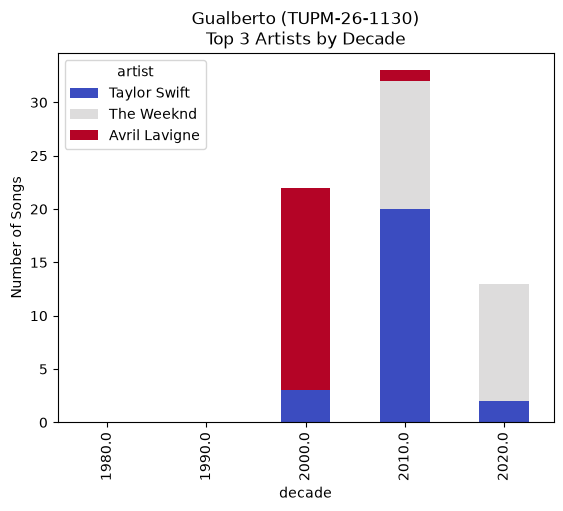

In [20]:
# Cell 20: Section IV #10 - Top 3 Artists by Decade
crosstab = pd.crosstab(df['decade'], df['artist'])
top3 = df['artist'].value_counts().head(3).index
crosstab[top3].plot(kind='bar', stacked=True, colormap='coolwarm')
plt.title(f"{student_name} ({student_id})\nTop 3 Artists by Decade")
plt.ylabel('Number of Songs')
plt.show()

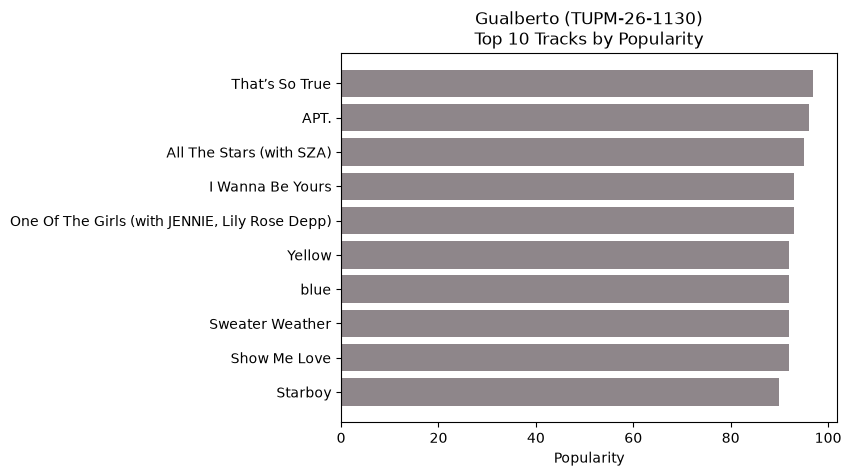

In [21]:
# Cell 21: Section IV #11 - Top 10 Tracks by Popularity
top_tracks = df.nlargest(10, 'popularity')
plt.barh(top_tracks['track_name'], top_tracks['popularity'], color=color1)
plt.xlabel('Popularity')
plt.title(f"{student_name} ({student_id})\nTop 10 Tracks by Popularity")
plt.gca().invert_yaxis()
plt.show()

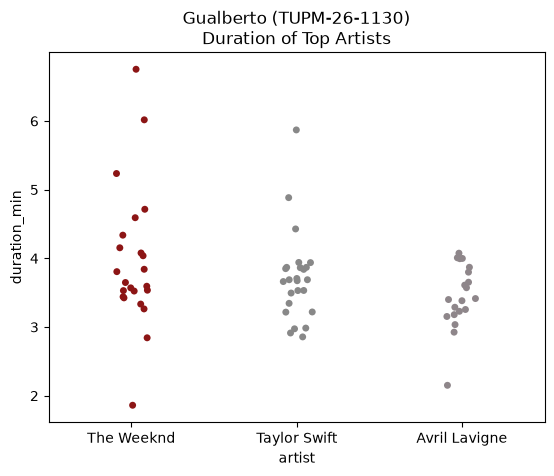

In [22]:
# Cell 22: Section IV #12 - Duration of Top Artists
top_artists = df['artist'].value_counts().head(3).index
sns.stripplot(data=df[df['artist'].isin(top_artists)], x='artist', y='duration_min',
              hue='artist', palette=['#8C1515', '#888888', color1], legend=False)
plt.title(f"{student_name} ({student_id})\nDuration of Top Artists")
plt.show()

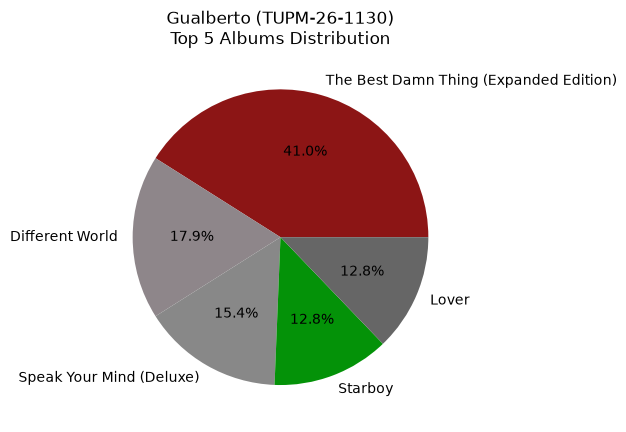

In [23]:
# Cell 23: Section IV #13 - Top 5 Albums Distribution
top_albums = df['album'].value_counts().head(5)
colors = ['#8C1515', color1, '#888888', color2, '#666666']
plt.pie(top_albums, labels=top_albums.index, autopct='%1.1f%%', colors=colors)
plt.title(f"{student_name} ({student_id})\nTop 5 Albums Distribution")
plt.show()

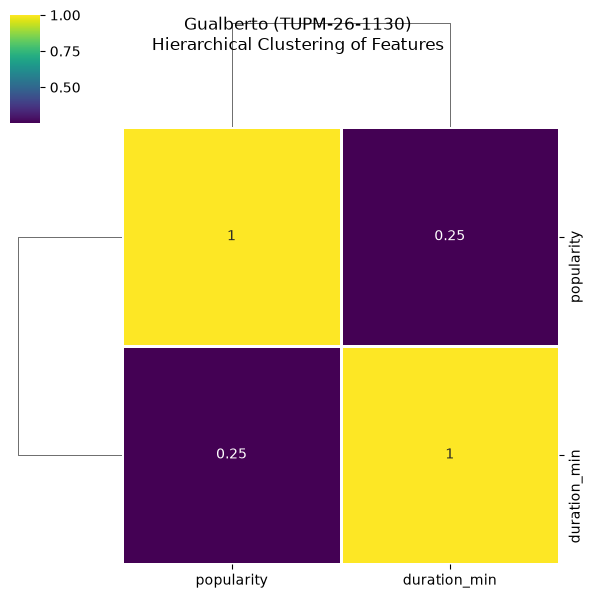

In [24]:
# Cell 24: Section IV #14 - Hierarchical Clustering of Features
numerical_cols = ['popularity', 'duration_min']
df_numeric = df[numerical_cols].dropna()
sns.clustermap(df_numeric.corr(), annot=True, cmap='viridis', linewidths=.75, figsize=(6, 6))
plt.suptitle(f"{student_name} ({student_id})\nHierarchical Clustering of Features")
plt.show()

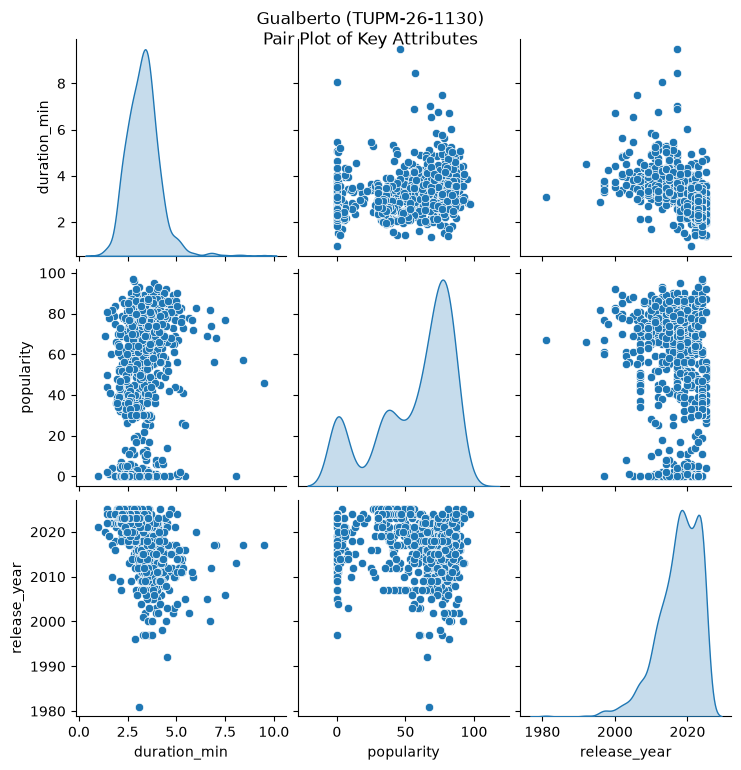

In [25]:
# Cell 25: Section IV #15 - Pair Plot of Key Attributes
g = sns.pairplot(df[['duration_min', 'popularity', 'release_year']].dropna(), diag_kind='kde')
g.figure.suptitle(f"{student_name} ({student_id})\nPair Plot of Key Attributes", y=1.02)
plt.show()

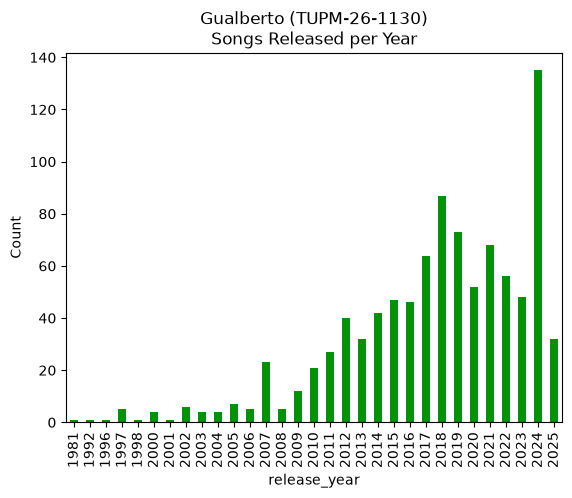

In [26]:
# Cell 26: Section IV #16 - Songs Released per Year
df['release_year'].dropna().astype(int).value_counts().sort_index().plot(kind='bar', color=color2)
plt.title(f"{student_name} ({student_id})\nSongs Released per Year")
plt.ylabel('Count')
plt.show()

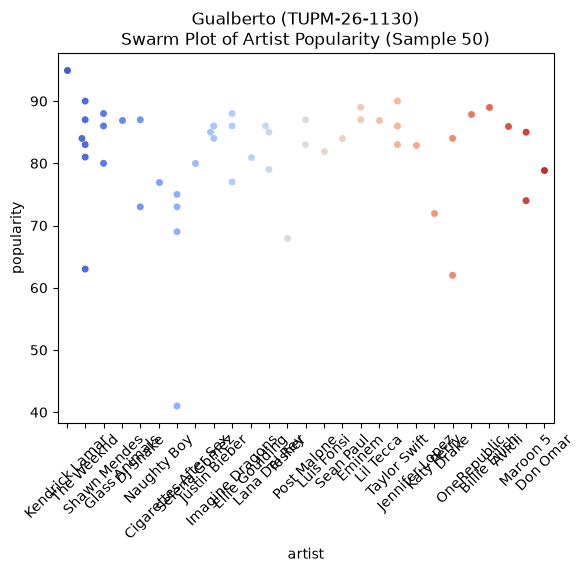

In [27]:
# Cell 27: Section IV #17 - Swarm Plot of Artist Popularity (Sample 50)
sns.swarmplot(data=df.head(50), x='artist', y='popularity',
              hue='artist', palette='coolwarm', legend=False)
plt.title(f"{student_name} ({student_id})\nSwarm Plot of Artist Popularity (Sample 50)")
plt.xticks(rotation=45)
plt.show()

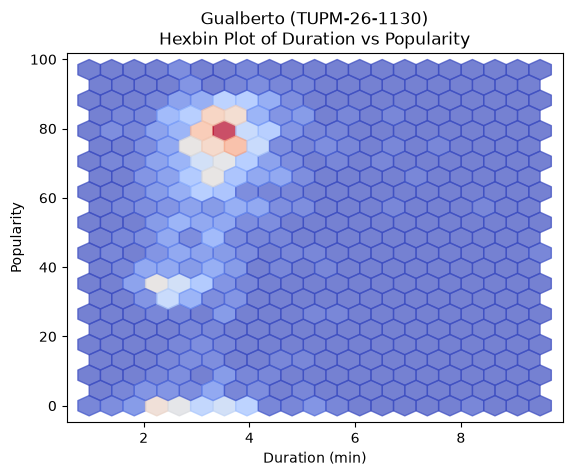

In [28]:
# Cell 28: Section IV #18 - Hexbin Plot of Duration vs Popularity
plt.hexbin(df['duration_min'], df['popularity'], gridsize=20, cmap='coolwarm', alpha=0.7)
plt.xlabel('Duration (min)')
plt.ylabel('Popularity')
plt.title(f"{student_name} ({student_id})\nHexbin Plot of Duration vs Popularity")
plt.show()

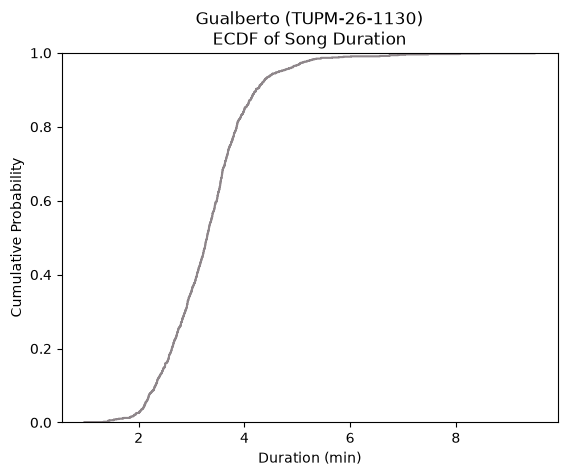

In [29]:
# Cell 29: Section IV #19 - ECDF of Song Duration
sns.ecdfplot(data=df, x='duration_min', color=color1)
plt.title(f"{student_name} ({student_id})\nECDF of Song Duration")
plt.xlabel('Duration (min)')
plt.ylabel('Cumulative Probability')
plt.show()

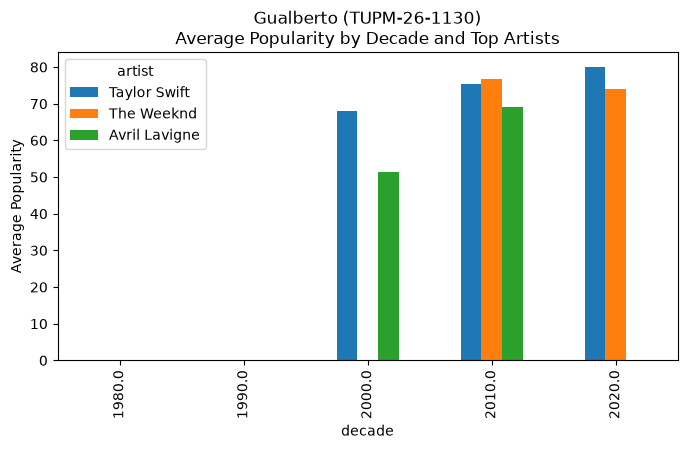

In [30]:
# Cell 30: Section IV #20 - Average Popularity by Decade and Top Artists
top3 = df['artist'].value_counts().head(3).index
avg_artist_decade = df.groupby(['decade', 'artist'])['popularity'].mean().unstack().fillna(0)
avg_artist_decade[top3].plot(kind='bar', figsize=(8, 4))
plt.title(f"{student_name} ({student_id})\nAverage Popularity by Decade and Top Artists")
plt.ylabel('Average Popularity')
plt.show()